In [98]:
# https://pyhank.readthedocs.io/en/latest/auto_examples/simple_example.html
# https://www.mdpi.com/2304-6732/12/4/306

#pip install pyhank
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
from pyhank import HankelTransform
import torch

### Useful functions & G-S

In [99]:
def KtoR(k, waveLength, focalLength):
    return waveLength * focalLength * k / (2 * np.pi)

def RtoK(r, waveLength, focalLength):
    return 2 * np.pi * r / (waveLength * focalLength)

In [100]:
def MSE_w(goalProfile, iterProfile, weights):

    # Donem mes pes als valors mes allunyats del centre, ja que son els que influiran 
    # mes en fer la revolucio del perfil

    return np.sum(weights * (goalProfile - iterProfile)**2)/(np.sum(weights * goalProfile**2) + 1e-15)

def GerchbergSaxton(inputProfile, goalFunction, transformer, radius = 100, maxiter = 10000, errMin = 1e-4, initialSlope = 8):

    # define transformer & scale
    N = len(goalFunction)
    r = transformer.r
    kr = transformer.kr

    # normalize target intensity
    P_in = 2 * np.pi * np.trapezoid(np.abs(inputProfile)**2 * r, r)
    P_goal = 2 * np.pi * np.trapezoid(np.abs(goalFunction)**2 * r, r)
    goalProfile = goalFunction * np.sqrt(P_in/P_goal)


    n = 2
    testfit = np.array([initialSlope*item*1e2 * (item*1e2)**n / ((item * 1e2)**n + 1) - 2.5 for item in r])
    # define initial DOE
    U_DOE = np.exp(1j * testfit)

    # definim ponderacions per MSE
    #slope = 1
    #weights = np.linspace(1, N*slope, N)
    weights = kr * np.gradient(kr) # gradient per no uniforme

    # CHAT---------------------------------------

    # Output of initial field
    U_initial = transformer.qdht(inputProfile)

    # Integration weights in Hankel frequency coordinates
    weights = kr * np.gradient(kr)

    # Match target power to the initial transformed field
    P_in = np.sum(weights * np.abs(U_initial)**2)
    P_goal = np.sum(weights * np.abs(goalFunction)**2)

    goalProfile = goalFunction * np.sqrt(P_in / P_goal)

    # ------------------

    for i in range(maxiter):

        # --- DOE PLANE

        # apply DOE phase
        U_tot = inputProfile * U_DOE

        # propagate to focal plane
        U_image = transformer.qdht(U_tot)

        # ---- IMAGE PLANE

        # Find new intensity
        U_im_abs = np.abs(U_image)
        I_found = U_im_abs**2

        # check for MSE with radial weighting
        error = MSE_w(goalProfile, U_im_abs, weights)

        # replace amplitude, retain phase
        U_image = goalProfile * np.exp(1j * np.angle(U_image))

        # Check for flatness
        #flatness = (max(I) - min(I))/(max(I) + min(I))

        if error < errMin:
            print("Converged with error < errMin")
            break

        # go back to DOE
        U_DOE = transformer.iqdht(U_image)
        U_DOE = np.exp(1j * np.angle(U_DOE))

    print("# iterations = ", i)
    print("Error = ", error)
    return U_DOE


def wrap(angles):
    return (angles + np.pi) % (2 * np.pi) - np.pi

### Class definition

In [101]:
class GS_DOE:
    def __init__(self, params):
        self.setParams(params)

    def setParams(self, params):
        self.fl = params["fl"]
        self.wl = params["wl"]
        self.rmax = params["rmax"]
        self.N = params["N"]
        self.w0 = params["w0"]
        self.wgoal = params["wgoal"]

    def setFocal(self, focal):
        self.fl = focal

    def setWl(self, wl):
        self.wl = wl

    def setW0(self, w0):
        self.w0 = w0

    def setrmax(self, rmax):
        self.rmax = rmax

    def makeProfiles(self, p = 3):
        self.transformer = HankelTransform(order=0, max_radius=self.rmax, n_points=self.N)
        self.r = self.transformer.r
        self.kr = self.transformer.kr
        
        # define input intensity profile
        self.inputAmp = np.exp(-(self.r/self.w0)**2)
        #self.inputAmp = np.sqrt(self.inputInt)

        # UNUSED, forma general per separacio irregular
        #U_in = interp1d(
        #    self.r, self.inputAmp,
        #    bounds_error=False,
        #    fill_value=0
        #)(r)

        # Convert spatial frequency to physical focal-plane radius
        self.rho = self.wl * self.fl * self.transformer.kr / (2*np.pi)

        self.goalProfile = np.exp(-(self.rho/self.wgoal)**(2*p))


    def showInputs(self):
        fig, ax = plt.subplots(1, 1, figsize = (6, 4))
        ax.plot(self.r*1e2, self.inputAmp, label = "Input amplitude")
        ax.plot(self.rho*1e2, self.goalProfile, label = "Goal amplitude")
        ax.legend(fontsize = 14)
        ax.set_xlabel("Radius (cm)", fontsize = 14)
        ax.set_ylabel("I/I$_0$", fontsize = 14)
        ax.set_xlim(0, np.max(self.r)*1e2)
        plt.show()

    def makeDOE(self, initialSlope = 8, maxiter = 10000, errMin = 1e-4):
        self.initialSlope = initialSlope
        self.DOE = GerchbergSaxton(self.inputAmp, self.goalProfile, self.transformer, radius = self.rmax, maxiter = maxiter, errMin = errMin, initialSlope = initialSlope)

    def showResults(self, wrapped = False):
        fig, axs = plt.subplots(1, 2, figsize = (12, 4))

        testfit = np.array([self.initialSlope*item*1e2 * (item*1e2)**2 / ((item * 1e2)**2 + 1) - 2.5 for item in self.r])

        if wrapped:
            axs[0].plot(self.r*1e2, np.angle(self.DOE), label = "DOE")
            testfit = wrap(testfit)
            axs[0].plot(self.r*1e2, testfit, label = "Initial fit")
        else:
            axs[0].plot(self.r*1e2, np.unwrap(np.angle(self.DOE)), label = "DOE")
            axs[0].plot(self.r*1e2, testfit, label = "Initial fit")
        axs[0].set_title("DOE phase profile")
        axs[0].set_xlabel("r (cm)", fontsize = 14)
        axs[0].set_ylabel("Phase (rad)", fontsize = 14)
        axs[0].set_xlim(0, np.max(self.r)*1e2)
        axs[0].legend()

        # test DOE
        U_converged = self.inputAmp * self.DOE
        U_image = self.transformer.qdht(U_converged)

        normImage = np.abs(U_image) / max(np.abs(U_image))
        goalImage = np.abs(self.goalProfile) / max(np.abs(self.goalProfile))

        axs[1].plot(self.rho*1e2, normImage**2, label = "Converged")
        axs[1].plot(self.rho*1e2, self.goalProfile**2, label = "Goal")
        axs[1].legend(fontsize = 14)
        axs[1].set_title("Image profile")
        axs[1].set_xlabel("Distance to center (cm)", fontsize = 14)
        axs[1].set_ylabel("I/I$_0$", fontsize = 14)
        axs[1].set_xlim(0, self.rmax*1e2)
        axs[1].set_ylim(-0.1, 1.1)
        axs[1].vlines(self.wgoal*1e2, -0.2, 1.2, ls = "--", color = "black")
        fig.show()

    def getDOE(self):
        return self.DOE

## DOE designer (Circular symmetry)

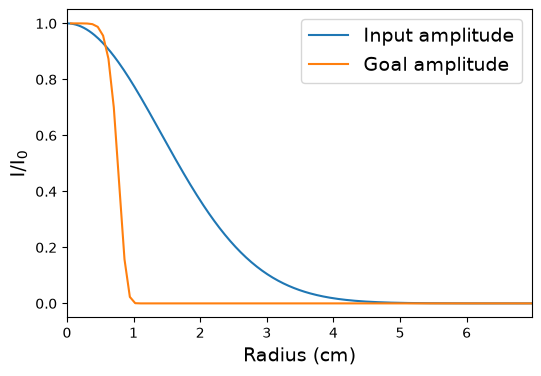

# iterations =  9999
Error =  0.0037889374712516185


In [128]:
f = 400e9 # Hz

params = {
    "fl": 15e-2, # cm
    "wl": 3e8/f,
    "rmax": 7e-2, # cm
    "N": 350,
    "w0": 0.02, # cm
    "wgoal": 0.008 # cm
}

DOE_maker = GS_DOE(params)
DOE_maker.makeProfiles(p = 4)
DOE_maker.showInputs()
DOE_maker.makeDOE(initialSlope = 4, maxiter = 10000)

C:\Users\PC\AppData\Local\Temp\ipykernel_23404\1113893144.py:95: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


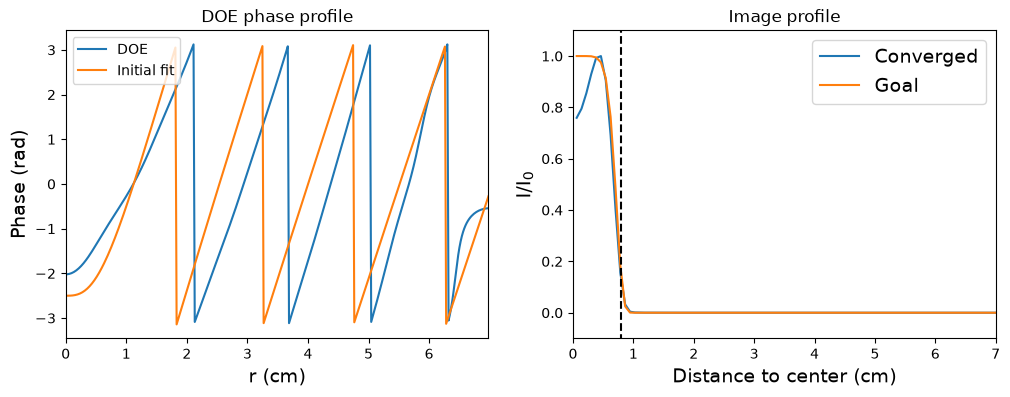

In [129]:
DOE_maker.showResults(wrapped = True)

---

## 2d DOE   

In [104]:
# for a transmissive DOE
def thickness(phase, n, wl):
    return wl * phase / (2 * np.pi * (n-1))

In [105]:
def radial_to_2d(profile):
    n = len(profile)
    y, x = np.ogrid[-(n-1):n, -(n-1):n]
    r = np.sqrt(x**2 + y**2)
    return profile[np.clip(np.rint(r).astype(int), 0, n-1)]

def genLensPhase(N, wl, fl, dx):
    y, x = np.ogrid[-(N-1):N, -(N-1):N]
    r = np.sqrt(x**2 + y**2) * dx
    return -np.pi * r**2 / (wl * fl)

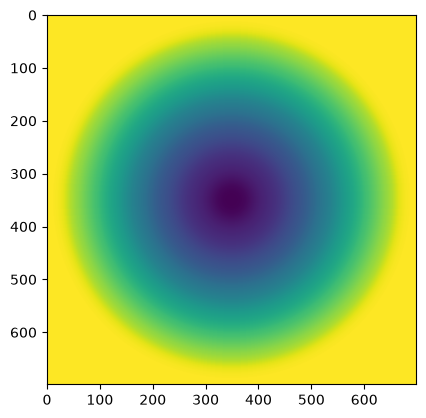

In [106]:
prova1 = radial_to_2d(np.unwrap(np.angle(DOE_maker.getDOE())))

plt.imshow(prova1)

In [118]:
import torchoptics
from torchoptics.profiles import gaussian, square, circle
from torchoptics.elements import PhaseModulator
from torchoptics import Field, System, visualize_tensor
device = "cuda" if torch.cuda.is_available() else "cpu"

dx = params['rmax'] / params['N']
torchoptics.set_default_spacing(dx)
torchoptics.set_default_wavelength(params['wl'])
shape = 2 * params['N'] - 1

# 1st version: one focus frequency
ph_lens = genLensPhase(params['N'], params['wl'], params['fl'], dx)
DOE_2D = torch.from_numpy(prova1) + ph_lens

waist_radius = params['w0']
source_profile = gaussian(shape, waist_radius=waist_radius).to(device)

input_field = Field(source_profile, z=0).to(device)
system = System(
    # Detach from any computation history, load directly as final phase
    PhaseModulator(DOE_2D, z=0),
).to(device)

output_field = system.measure_at_z(input_field, params['fl'])




C:\Users\PC\AppData\Local\Temp\ipykernel_23404\1957528755.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  DOE_2D = torch.from_numpy(prova1) + ph_lens


Text(0.5, 1.0, 'Output intensity')

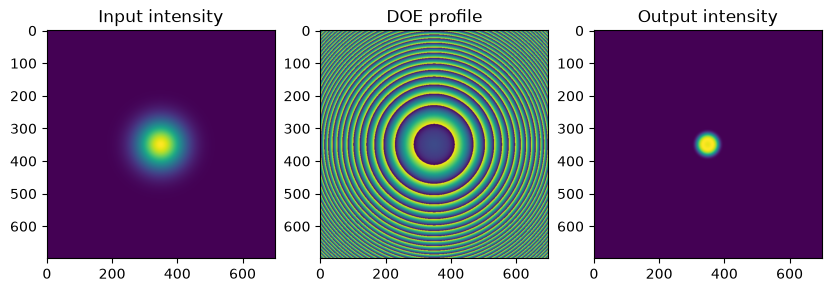

In [119]:
fig, ax = plt.subplots(1,3,figsize = (10,3))
ax[0].imshow(input_field.intensity().detach().numpy())
ax[0].set_title("Input intensity")

ax[1].imshow(wrap(DOE_2D))
ax[1].set_title("DOE profile")

ax[2].imshow(output_field.intensity().detach().numpy())
ax[2].set_title("Output intensity")

---

### Wideband DOE?